# Workshop 3 — Fase A: Ingeniería de Características y Entrenamiento del Modelo

**Objetivo:**  
1. Explorar las relaciones estadísticas entre los indicadores socioeconómicos y el `happiness_score` en el dataset armonizado (`data/processed/happiness_unified.csv`).  
2. Seleccionar y justificar las características de entrada evitando fuga de datos (*target leakage*).  
3. Encapsular el preprocesamiento y un modelo de regresión simple en un `Pipeline` reproducible de `scikit-learn` (división **70% entrenamiento / 30% prueba**).  
4. Evaluar métricas (`MAE`, `RMSE`, `R²`) y serializar el pipeline entrenado en `models/model.pkl` para inferencia en tiempo real desde Apache Kafka.

In [1]:
from datetime import datetime, timezone
import json
from pathlib import Path

from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", context="notebook")


def resolve_project_root() -> Path:
    """Resuelve la raíz del proyecto sin importar si Jupyter inicia en /notebooks o en la raíz."""
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent):
        if (candidate / "data" / "processed").exists():
            return candidate
    raise FileNotFoundError(
        "No se encontró la carpeta 'data/processed'. Ejecuta primero notebooks/eda.ipynb."
    )


PROJECT_ROOT = resolve_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "happiness_unified.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "model.pkl"
METADATA_PATH = MODELS_DIR / "model_metadata.json"

df = pd.read_csv(DATA_PATH)
assert df.isna().sum().sum() == 0, "El dataset procesado contiene valores nulos inesperados."
print(f"Dataset cargado: {df.shape[0]} registros x {df.shape[1]} columnas")
display(df.head())

Dataset cargado: 782 registros x 9 columnas


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Afghanistan,2015,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719,3.575
1,Albania,2015,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413,4.959
2,Algeria,2015,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,5.605
3,Angola,2015,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122,4.033
4,Argentina,2015,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484,6.574


## Paso 3 — Ingeniería de Características y Análisis de Relaciones

Analizamos estadísticos descriptivos, correlaciones lineales y diagramas de dispersión para fundamentar la selección de variables.

Estadísticos descriptivos del dataset unificado:


,count,mean,std,min,25%,50%,75%,max
gdp,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
family,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
health,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption,782.0,0.125710,0.106027,0.000,0.054250,0.091033,0.156243,0.551910
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000



Correlación de cada variable con happiness_score:


,pearson_corr
happiness_score,1.000000
gdp,0.789284
health,0.742456
family,0.648799
freedom,0.551258
corruption,0.400189
generosity,0.137578
year,0.007065


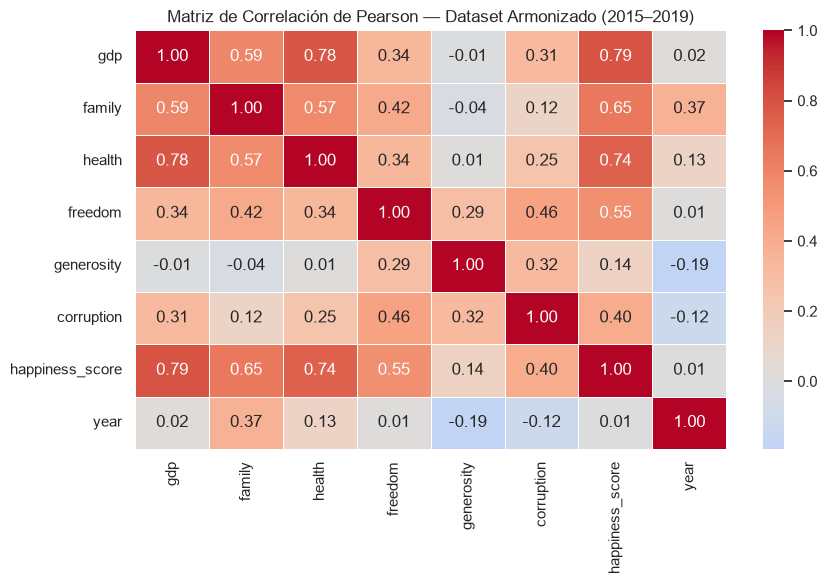

In [2]:
numeric_cols = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]
print("Estadísticos descriptivos del dataset unificado:")
display(df[numeric_cols].describe().T)

corr_matrix = df[numeric_cols + ["year"]].corr()
print("\nCorrelación de cada variable con happiness_score:")
display(corr_matrix["happiness_score"].sort_values(ascending=False).to_frame("pearson_corr"))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matriz de Correlación de Pearson — Dataset Armonizado (2015–2019)")
plt.tight_layout()
plt.show()

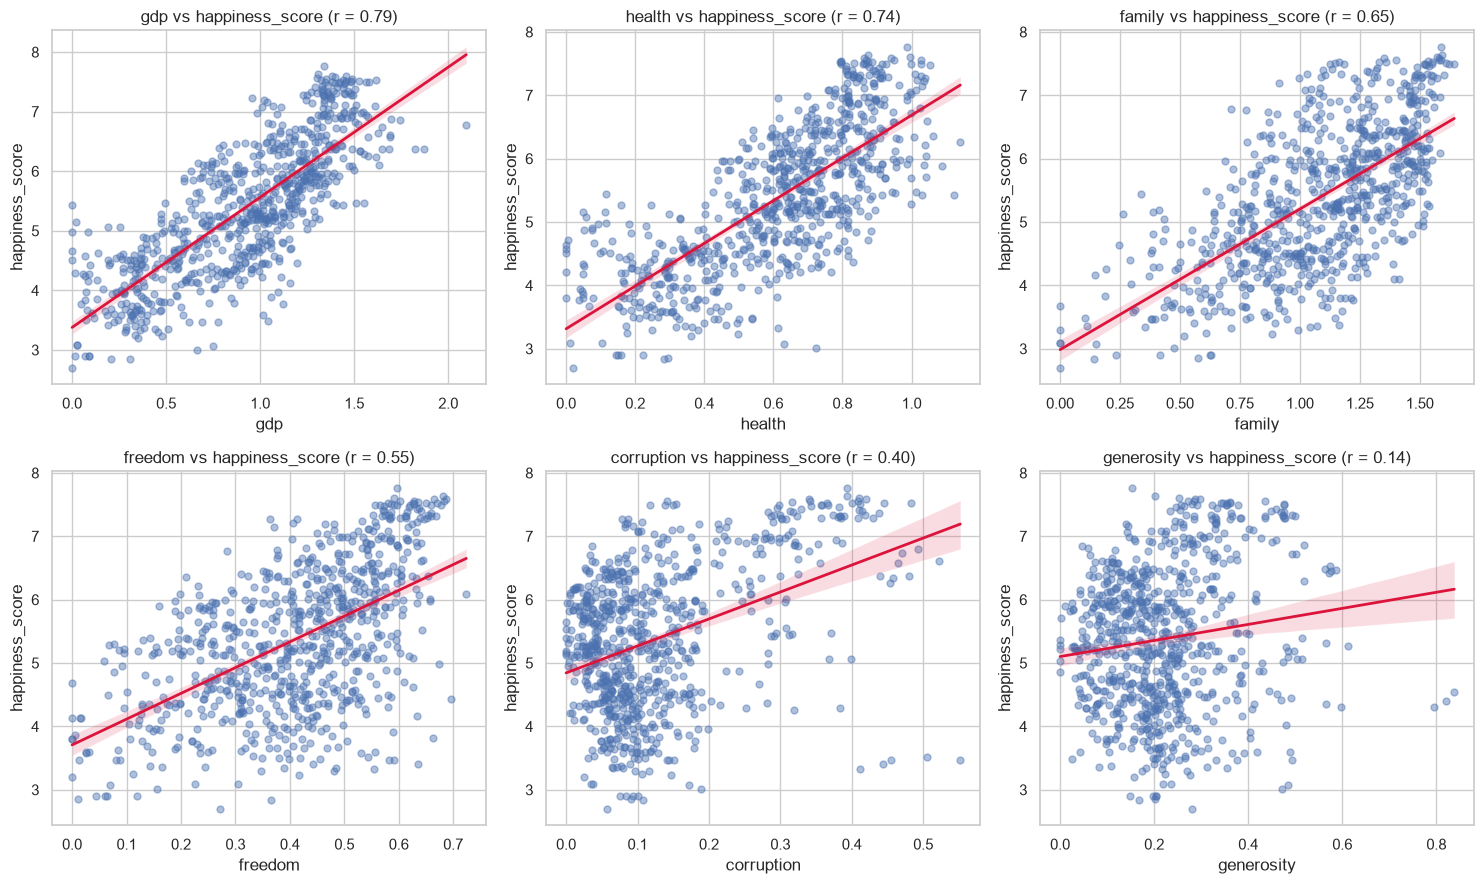

In [3]:
# Visualización de relaciones entre los principales predictores y happiness_score
top_predictors = ["gdp", "health", "family", "freedom", "corruption", "generosity"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flatten(), top_predictors):
    sns.regplot(
        data=df,
        x=col,
        y="happiness_score",
        ax=ax,
        scatter_kws={"alpha": 0.45, "s": 25},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    corr_val = df[col].corr(df["happiness_score"])
    ax.set_title(f"{col} vs happiness_score (r = {corr_val:.2f})")

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# SELECCIÓN DE CARACTERÍSTICAS Y PREVENCIÓN DE FUGA DE DATOS (TARGET LEAKAGE)
# ==============================================================================
#
# 1. FEATURE_COLUMNS seleccionadas (orden estricto compartido con consumer.py):
#    ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
#    - Justificación analítica: representan los 6 factores explicativos estructurales del World Happiness Report,
#      presentan consistencia en los 5 años (2015–2019) y muestran relación positiva con 'happiness_score'
#      (especialmente gdp r≈0.79, health r≈0.74, family r≈0.65, freedom r≈0.55, corruption r≈0.40).
#    - Justificación de arquitectura (Streaming Contract): coinciden 1 a 1 en nombre y tipo numérico con el
#      Event Contract definido para el tópico 'happiness-events' en Kafka.
#
# 2. Exclusión de 'country' como feature del modelo:
#    - Aunque es una variable categórica relevante para análisis BI, codificar ~164 países sobre 782 observaciones
#      introduciría alta dimensionalidad y sobreajuste (el modelo memorizaría países en vez de aprender la relación
#      socioeconómica). Además, en streaming en tiempo real un país nuevo o variante no vista degradaría la
#      inferencia. Por ello, 'country' se preserva estrictamente como llave de partición en Kafka y dimensión 'dim_country'.
#    - Consecuencia: no se requiere OneHotEncoder/OrdinalEncoder en el Pipeline.
#
# 3. Exclusión de 'year' como feature del modelo:
#    - Su correlación con 'happiness_score' es prácticamente nula (r≈0.007). Incluir 'year' como variable numérica
#      generaría riesgo de extrapolación artificial cuando lleguen eventos simulados con años futuros (>2019).
#
# 4. Prevención estricta de Target Leakage:
#    - 'happiness_score' ('actual_happiness_score' en el JSON de Kafka) es exclusivamente la variable objetivo 'y'
#      y NUNCA entra en 'X'. Las columnas de ranking, intervalos de confianza y residual de Distopía fueron removidas
#      en la Fase A (eda.ipynb) precisamente para evitar cualquier filtración del objetivo.
#
# 5. Estrategia de escalamiento y ordenamiento de features:
#    - Aunque los indicadores oscilan en escalas acotadas, sus dispersiones difieren (ej. gdp hasta ~2.10 vs
#      corruption hasta ~0.55). Aplicar StandardScaler DENTRO del Pipeline (ajustado únicamente con X_train)
#      normaliza las magnitudes sin fugar información del conjunto de prueba hacia entrenamiento y garantiza
#      reproducibilidad exacta al consumir 'model.pkl' desde Kafka.

FEATURE_COLUMNS = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET_COLUMN = "happiness_score"

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].copy()

print("Features de entrada (X):", list(X.columns))
print("Variable objetivo (y):", TARGET_COLUMN)

Features de entrada (X): ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
Variable objetivo (y): happiness_score


## Paso 4 — Entrenamiento, Evaluación y Serialización del Pipeline de Regresión

Dividimos los datos en **70% entrenamiento** y **30% prueba**, entrenamos un `Pipeline` simple con `LinearRegression` (con comparación de referencia frente a `DecisionTreeRegressor` y `RandomForestRegressor`) y serializamos el artefacto final en `models/model.pkl`.

In [5]:
# División reproducible 70% entrenamiento / 30% prueba según recomendación del taller
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
)

print(f"Tamaño Train (70%): {X_train.shape[0]} filas")
print(f"Tamaño Test  (30%): {X_test.shape[0]} filas")


def build_regression_pipeline(regressor) -> Pipeline:
    """Construye un Pipeline reproducible con imputación defensiva, escalamiento y regresor."""
    # JUSTIFICACIÓN DEL PIPELINE:
    # - SimpleImputer(strategy='median'): salvaguarda MLOps ante eventuales nulos si el modelo se reentrena
    #   con nuevos lotes históricos (en inferencia streaming, el Event Contract rechaza nulos antes de predecir).
    # - StandardScaler(): estandariza media 0 y varianza 1 usando únicamente estadísticas de X_train.
    # - regressor: estimador de regresión encapsulado en el mismo artefacto serializable.
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("regressor", regressor),
        ]
    )


def evaluate_predictions(y_true: pd.Series, y_pred: np.ndarray) -> dict[str, float]:
    """Calcula MAE, RMSE y R² de forma compatible con cualquier versión de scikit-learn."""
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

Tamaño Train (70%): 547 filas
Tamaño Test  (30%): 235 filas


In [6]:
# Comparativa breve de los 3 modelos sugeridos en el taller (sin optimización compleja de hiperparámetros)
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

comparison_results = []
trained_pipelines = {}

for name, estimator in candidate_models.items():
    pipe = build_regression_pipeline(estimator)
    # Se entrena pasando DataFrame con nombres explícitos para conservar pipe.feature_names_in_
    pipe.fit(X_train[FEATURE_COLUMNS], y_train)
    trained_pipelines[name] = pipe

    train_metrics = evaluate_predictions(y_train, pipe.predict(X_train[FEATURE_COLUMNS]))
    test_metrics = evaluate_predictions(y_test, pipe.predict(X_test[FEATURE_COLUMNS]))
    comparison_results.append({
        "Model": name,
        "Train_MAE": round(train_metrics["MAE"], 4),
        "Train_RMSE": round(train_metrics["RMSE"], 4),
        "Train_R2": round(train_metrics["R2"], 4),
        "Test_MAE": round(test_metrics["MAE"], 4),
        "Test_RMSE": round(test_metrics["RMSE"], 4),
        "Test_R2": round(test_metrics["R2"], 4),
    })

comparison_df = pd.DataFrame(comparison_results)
print("Comparativa de desempeño (70/30 split):")
display(comparison_df)

# JUSTIFICACIÓN DE LA SELECCIÓN DEL MODELO FINAL (LinearRegression):
# El objetivo principal del taller es una arquitectura streaming limpia, reproducible y de baja latencia,
# no maximizar complejidad predictiva. LinearRegression ofrece:
# 1. Generalización estable sin brecha de sobreajuste entre Train y Test (a diferencia de árboles profundos).
# 2. Inferencia determinista en microsegundos para el consumidor de Kafka en tiempo real.
# 3. Coeficientes estandarizados directamente interpretables para explicar el aporte de cada indicador.
selected_model_name = "Linear Regression"
final_pipeline = trained_pipelines[selected_model_name]
y_pred_test = final_pipeline.predict(X_test[FEATURE_COLUMNS])
final_metrics = evaluate_predictions(y_test, y_pred_test)

print(f"\nModelo seleccionado para producción: {selected_model_name}")
print(f"Métricas Test -> MAE: {final_metrics['MAE']:.4f} | RMSE: {final_metrics['RMSE']:.4f} | R²: {final_metrics['R2']:.4f}")

Comparativa de desempeño (70/30 split):


,Model,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,0.4245,0.5454,0.7647,0.4288,0.5538,0.7599
1,Decision Tree Regressor,0.3458,0.4424,0.8452,0.4701,0.6049,0.7136
2,Random Forest Regressor,0.1418,0.1862,0.9726,0.3983,0.5085,0.7976



Modelo seleccionado para producción: Linear Regression
Métricas Test -> MAE: 0.4288 | RMSE: 0.5538 | R²: 0.7599


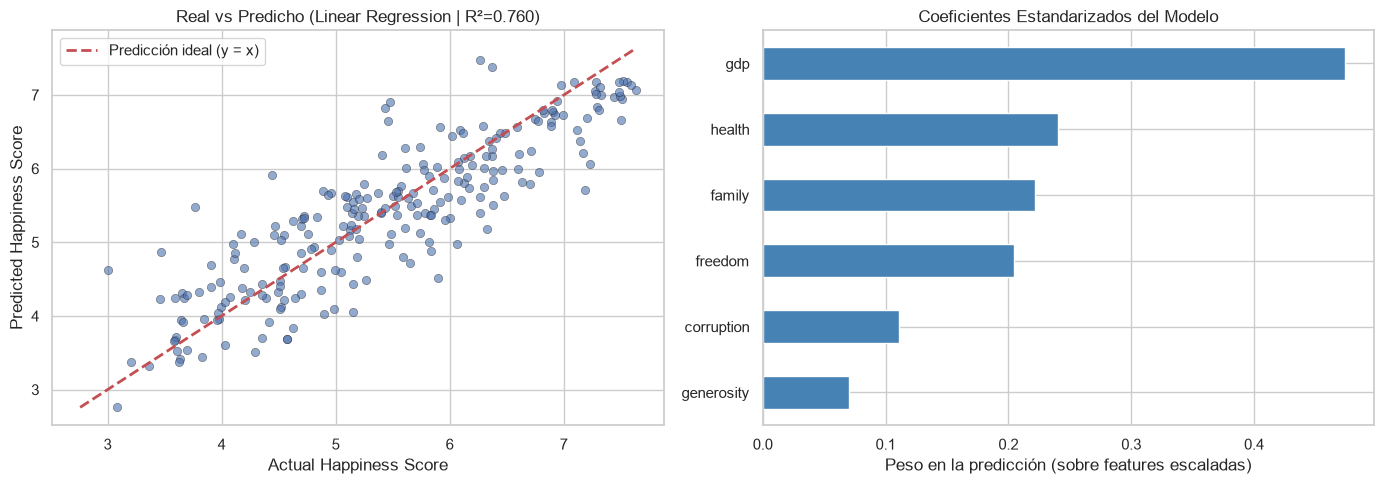

In [7]:
# Diagnóstico visual de predicciones y coeficientes estandarizados del modelo seleccionado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Real vs Predicho
axes[0].scatter(y_test, y_pred_test, alpha=0.6, edgecolor="k", linewidth=0.4)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Predicción ideal (y = x)")
axes[0].set_title(f"Real vs Predicho ({selected_model_name} | R²={final_metrics['R2']:.3f})")
axes[0].set_xlabel("Actual Happiness Score")
axes[0].set_ylabel("Predicted Happiness Score")
axes[0].legend()

# 2. Importancia relativa (coeficientes estandarizados)
coefs = pd.Series(
    final_pipeline.named_steps["regressor"].coef_,
    index=FEATURE_COLUMNS,
).sort_values()
coefs.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Coeficientes Estandarizados del Modelo")
axes[1].set_xlabel("Peso en la predicción (sobre features escaladas)")

plt.tight_layout()
plt.show()

In [8]:
# ==============================================================================
# SERIALIZACIÓN DEL PIPELINE COMPLETO Y PRUEBA DE INFERENCIA (SMOKE TEST)
# ==============================================================================
joblib.dump(final_pipeline, MODEL_PATH)

metadata = {
    "model_type": selected_model_name,
    "sklearn_version": sklearn.__version__,
    "feature_order": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_metrics": {k.lower(): round(v, 6) for k, v in final_metrics.items()},
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print(f"Pipeline serializado en: {MODEL_PATH}")
print(f"Metadatos guardados en: {METADATA_PATH}")

# Smoke test: simular exactamente cómo consumer.py cargará model.pkl y predecirá un evento JSON de Kafka
loaded_pipeline = joblib.load(MODEL_PATH)
assert list(loaded_pipeline.feature_names_in_) == FEATURE_COLUMNS, "Orden de features inconsistente en model.pkl."

sample_kafka_event = {
    "event_id": "E001",
    "country": "Colombia",
    "year": 2019,
    "gdp": 1.2,
    "family": 0.8,
    "health": 0.9,
    "freedom": 0.6,
    "generosity": 0.3,
    "corruption": 0.1,
    "actual_happiness_score": 6.2,
    "event_time": "2026-10-30T15:30:00",
}

# Extraer únicamente las features respetando el orden exacto de entrenamiento
inference_df = pd.DataFrame(
    [[sample_kafka_event[col] for col in loaded_pipeline.feature_names_in_]],
    columns=list(loaded_pipeline.feature_names_in_),
)
predicted_score = float(loaded_pipeline.predict(inference_df)[0])
prediction_error = abs(sample_kafka_event["actual_happiness_score"] - predicted_score)

print(f"\nSmoke test evento {sample_kafka_event['event_id']} ({sample_kafka_event['country']}):")
print(f"  Actual Score   : {sample_kafka_event['actual_happiness_score']:.4f}")
print(f"  Predicted Score: {predicted_score:.4f}")
print(f"  Abs Error      : {prediction_error:.4f}")

Pipeline serializado en: C:\Users\jagui\Desktop\UNIVERSIDAD\ETL\workshop_3\models\model.pkl
Metadatos guardados en: C:\Users\jagui\Desktop\UNIVERSIDAD\ETL\workshop_3\models\model_metadata.json

Smoke test evento E001 (Colombia):
  Actual Score   : 6.2000
  Predicted Score: 6.0607
  Abs Error      : 0.1393
